# DATA-445: In-Class Assignment 17

**1.** Consider the `customers.csv` datafile. This file contains information related to customers' activity on a company website. Below are the description of the variables.

- `ID:` customer ID
- `Visit_Time:` The number of visits to the company's website in a given month.
- `Average_Expense:` The average amount of money that the customer has spend.
- `Sex:` gender of the customer (0: female, 1: male).
- `Age:` age of the customer.

**In Python**, answer the following:

**(a)** (3 points) Using the `pandas` library, read the csv file and create a data-frame called `customers`.

In [1]:

import pandas as pd 

customers = pd.read_csv("customers.csv")
customers.head()

,ID,Visit_Time,Average_Expense,Sex,Age
0,1,3,5.7,0,10
1,2,5,14.5,0,27
2,3,16,33.5,0,32
3,4,5,15.9,0,30
4,5,16,24.9,0,23


**(b)** (3 points) Using the appropriate Python commands, remove the `ID` variable.

In [2]:

customers = customers.drop(columns=["ID"], axis=1)
customers.head()

,Visit_Time,Average_Expense,Sex,Age
0,3,5.7,0,10
1,5,14.5,0,27
2,16,33.5,0,32
3,5,15.9,0,30
4,16,24.9,0,23


**(c)** (5 points) Using the appropriate standardization formula, put all the variables on the same scale. *Hint:* Notice that `Sex` is a 0-1 variable.

In [3]:

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
customers[["Visit_Time", "Average_Expense", "Age"]] = scaler.fit_transform(customers[["Visit_Time", "Average_Expense", "Age"]])
customers.head()

,Visit_Time,Average_Expense,Sex,Age
0,0.117647,0.041096,0,0.051282
1,0.235294,0.342466,0,0.487179
2,0.882353,0.993151,0,0.615385
3,0.235294,0.390411,0,0.564103
4,0.882353,0.698630,0,0.384615


**(d)** (8 points) Using the silhouette score, estimate the number of cluster for this dataset. Consider 2 to 20 clusters. Make sure to use `n_init=20`.

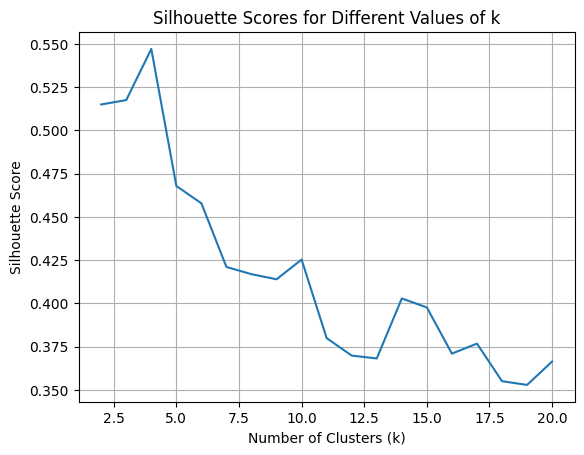

In [4]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sil_scores = []
for k in range(2, 21):
    
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    kmeans.fit(customers)
    sil_scores.append(silhouette_score(customers, kmeans.labels_))
    
import matplotlib.pyplot as plt

plt.plot(range(2, 21), sil_scores)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for Different Values of k")
plt.grid(True)
plt.show();

**(e)** (6 points) Using the `cmeans` function from the `skfuzzy.cluster` library, cluster the customers into the number of clusters estimated from part (d).

In [11]:
from skfuzzy.cluster import cmeans

# Fitting fuzzy c-means clustering
fc, W, u0, d, jm, p, pc = cmeans(
    customers.T, c=4, m=1.25, error=0.0001, maxiter=1000, seed=42
)

In [12]:
W.shape

(4, 60)

In [13]:
W[0]

array([1.15123501e-03, 2.15570715e-05, 4.79200416e-02, 5.42094827e-05,
       2.02666717e-03, 1.55442314e-04, 3.96219641e-03, 1.28494473e-04,
       1.75331481e-05, 1.14632527e-03, 2.79694801e-04, 1.18702076e-04,
       3.96219641e-03, 3.99881917e-07, 1.42243670e-04, 4.01795059e-04,
       1.94874234e-04, 6.36400803e-09, 4.29053449e-03, 9.69177180e-01,
       3.53592186e-07, 9.83756672e-01, 1.02211667e-10, 9.90954345e-01,
       9.99977624e-01, 1.35333031e-09, 3.21417974e-06, 9.99662944e-01,
       7.77663247e-06, 2.75204956e-07, 9.43079690e-05, 9.99996703e-01,
       9.99998386e-01, 9.94415330e-01, 2.75204956e-07, 9.10868237e-07,
       9.99465366e-01, 9.34433370e-05, 2.57052181e-06, 3.53592186e-07,
       3.67942292e-09, 1.31332155e-06, 3.76433363e-08, 5.24332460e-05,
       9.99576297e-01, 9.99662944e-01, 3.53837310e-02, 3.78935968e-06,
       1.06023566e-07, 9.90954345e-01, 9.44506579e-11, 7.10181442e-01,
       9.99208178e-01, 1.95160723e-06, 4.88118141e-03, 3.83589396e-08,
      

**(f)** (10 points) Change the likelihoods to cluster labels using 70% as threshold. Describe each of the clusters from part (d).

In [14]:
import numpy as np

customers["Cluster"] = np.nan

# Changing likelihoods to labels
customers["Cluster"] = np.where(W[0] > 0.7, 0, customers["Cluster"])
customers["Cluster"] = np.where(W[1] > 0.7, 1, customers["Cluster"])
customers["Cluster"] = np.where(W[2] > 0.7, 2, customers["Cluster"])
customers["Cluster"] = np.where(W[3] > 0.7, 3, customers["Cluster"])

# Checking for proportion of points assigned to each cluster
customers["Cluster"].value_counts(normalize=True)


Cluster
3.0    0.316667
0.0    0.266667
1.0    0.250000
2.0    0.166667
Name: proportion, dtype: float64